# DiffusionCB — 1-qubit CB harness

Trimmed clone of `CB/CB.ipynb` (1-qubit sim only). Project spec:
[`nonmarkovian_cb_diffusion_spec.md`](nonmarkovian_cb_diffusion_spec.md).

## Primer — one CB run

CB measures the per-Pauli fidelities **λ_P** that Standard RB averages away (SPAM-robust).

| symbol | what it is |
|---|---|
| **G** | gate / cycle **under test** (`I`, `H`) |
| **P** | **probe** Pauli — prep its +1 eigenstate, measure it (`X`,`Y`,`Z`) |
| **Rᵢ** | **random Pauli** twirl, fresh per cycle, uniform on `{I,X,Y,Z}` |

**Dressed cycle** = G wrapped by twirls `Rᵢ·G·Rᵢ₊₁` (randomized compiling → noise looks Pauli).

```
q0: ─[H]─[R0]─[G]─[R1]─[G]─[R2]─[H]─[M]      # P=X, m=2
     └prep┘ └─── dressed × m ───┘ └meas┘     # m copies of G, m+1 twirls
```

Each run → one overlap `f_{P,m,l} = Tr[C(P)·C̃(ρ)]` (= +1 if noiseless); average over `l=1..L` twirls → `F_m`.

`m` = # of G's. Run at short **m1** & long **m2**; SPAM cancels in the ratio:
`λ_P = (F_m2 / F_m1)^(1/(m2−m1))`.


In [1]:
from cb_harness import *


Cycle I (order 1), 1 qubit — expected vs measured λ_P
Running for 3 Paulis: ['X', 'Y', 'Z']
Drawing for P=X, m=2, random_paulis=['I', 'Z', 'Y']


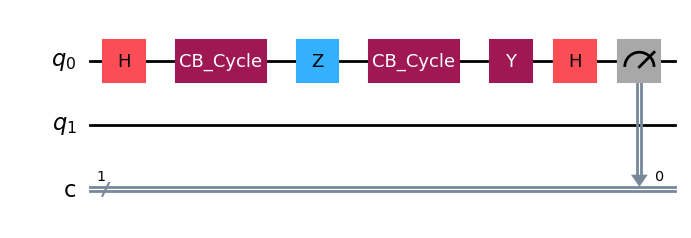

[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.7s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.0s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.3s)

  depolarizing
  P      expected  measured        Δ
  X        0.9500    0.9502  +0.0002
  Y        0.9500    0.9508  +0.0008
  Z        0.9500    0.9489  -0.0011
--------------------------------------------
  F_RC     0.9500    0.9500  -0.0000
Running for 3 Paulis: ['X', 'Y', 'Z']
[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.4s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.7s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.0s)

  dephasing
  P      expected  measured        Δ
  X        0.9000    0.9003  +0.0003
  Y        0.9000    0.8978  -0.0022
  Z        1.0000    1.0000  +0.0000
--------------------------------------------
  F_RC     0.9333    0.9327  -0.0006
Running for 3 Paulis: ['X', 'Y', 'Z']
[ 1/3] P=X    m=[2, 4, 6, 8, 12, 

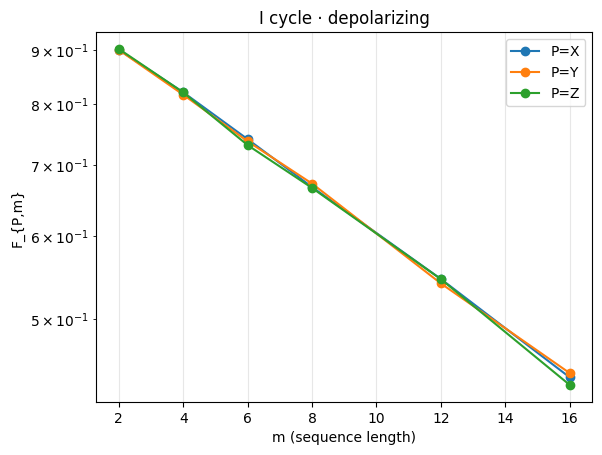

In [2]:
# ══════════════════════════════ DRIVER ══════════════════════════════


# (terminology + one-circuit primer: see the top markdown cell)

# --- Noise on G. CB measures lambda_P = survival of P-component:  Lambda(P) = lambda_P * P.
#"Channels preserve I" is the statement λ_I = 1 — and that's automatic, regardless of p_I: λ_I = p_I + p_X + p_Y + p_Z = (1−q) + q = 1 
#
# lambda_P = P(errors COMMUTING with P) - P(errors ANTICOMMUTING with P)
# commute: X~I,X | Y~I,Y | Z~I,Z ; each anticommutes with the other two)
# lambda_I = 1 <- always; I never decays, so not measured
#       lambda_X = (pI+pX) - (pY+pZ)
#       lambda_Y = (pI+pY) - (pX+pZ)
#       lambda_Z = (pI+pZ) - (pX+pY)
# 
# expected CB output (verify against this): order is (λ_X, λ_Y, λ_Z)
# interestingly e.g Z damages X and Y and Z is left alone e.g. dephasing
#   depolarizing p {"kind":"depolarizing","p":p} -> (1-p, 1-p, 1-p)
#   dephasing-q {"kind":"pauli","probs":{"I":1-q,"Z":q}} -> (1-2q,  1-2q,  1)
#   bit-flip-q {"kind":"pauli","probs":{"I":1-q,"X":q}} -> (1,1-2q,  1-2q)
#   biased {"I":.90,"X":.03,"Y":.02,"Z":.05} -> (0.86,  0.84,  0.90)
CYCLE_LABEL = "CB_Cycle"

noises = {
    "depolarizing": {"kind":"depolarizing", "p":0.05},
    "dephasing":    {"kind":"pauli", "probs":{"I":0.95, "Z":0.05}},
    "bit_flip":     {"kind":"pauli", "probs":{"I":0.95, "X":0.05}},
    "biased":       {"kind":"pauli", "probs":{"I":0.90, "X":0.03, "Y":0.02, "Z":0.05}},
}


cfg = CBConfig(n_sys_qubits=1, n_env=1, shots=1024, m_list=(2, 4, 6, 8, 12, 16), L=30, K=30, rng=rng, verbose=True,label=CYCLE_LABEL)

all_records = run_markovian_experiment(cfg, ["I", "H"], noises)


plot_decay(all_records[("I", "depolarizing")], cfg, title="I cycle · depolarizing")

Running for 3 Paulis: ['X', 'Y', 'Z']
Drawing for P=X, m=2, random_paulis=['I', 'Z', 'Y']


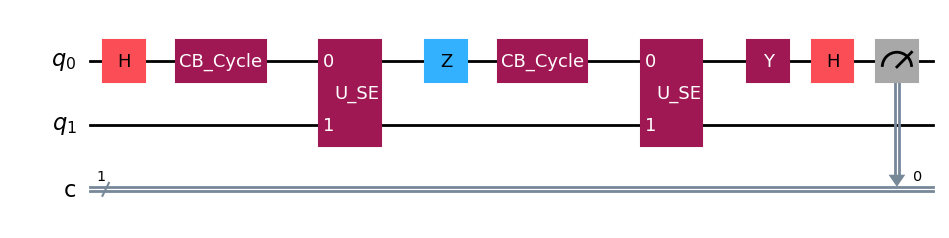

[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.4s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.7s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.1s)


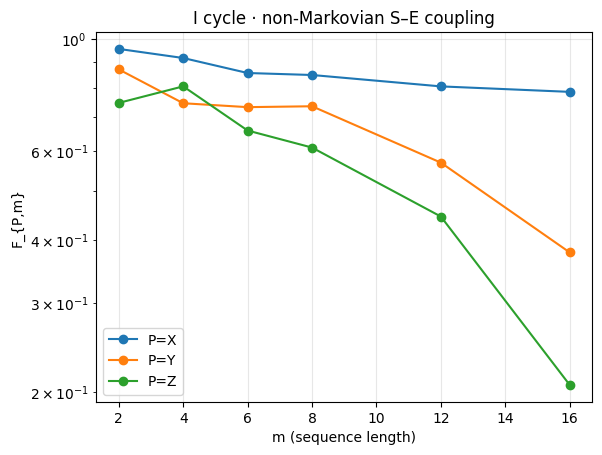

In [3]:
# Non markovian driver

nonm_rng = np.random.default_rng(42)
nonm_cfg = CBConfig(n_sys_qubits=1, n_env=1, shots=1024, m_list=(2, 4, 6, 8, 12, 16), L=30, K=30, rng=nonm_rng, verbose=True, label=CYCLE_LABEL)

delta = 0.1
U_SE = couple_with_env(delta)
random_paulis = make_paulis(nonm_cfg.n_sys_qubits, nonm_cfg.rng, nonm_cfg.K)
cycle="I"
G_map, _ = make_cycle(cycle, nonm_cfg.n_sys_qubits)
G_gate = UnitaryGate(Operator(G_map).data, label=nonm_cfg.label)
sampler = AerSampler()
nonm_cfg.env_coupling_gate = U_SE
nonm_cfg.reset_env = False
# run + plot
record_runs = run_cb(random_paulis, nonm_cfg, G_map, G_gate, sampler)
plot_decay(record_runs, nonm_cfg, title="I cycle · non-Markovian S–E coupling")


Running for 3 Paulis: ['X', 'Y', 'Z']
Drawing for P=X, m=2, random_paulis=['I', 'Z', 'Y']


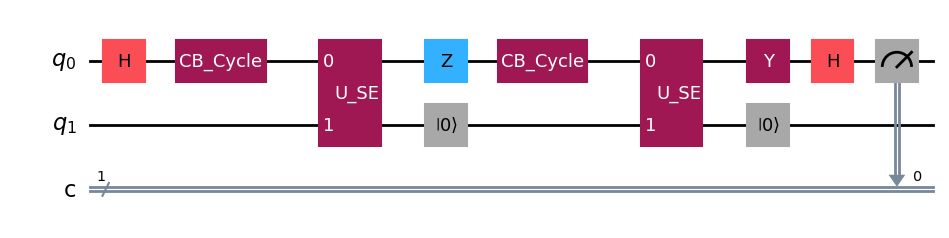

[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 4.8s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 9.6s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 14.8s)


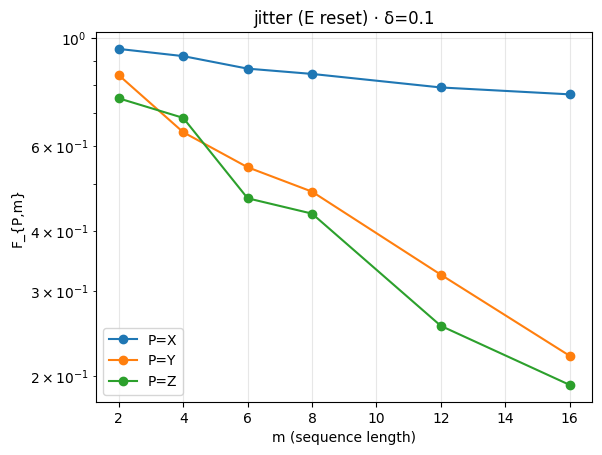

In [4]:
# Jitter - Driver Markovian

# --- driver: JITTER (self-contained; matches memory's delta) ---
delta      = 0.1                                  # match memory
jit_rng    = np.random.default_rng(42)            # same seed → same twirls as memory
jit_cfg    = CBConfig(n_sys_qubits=1, n_env=1, shots=1024,
                      m_list=(2,4,6,8,12,16), L=30, K=30,
                      rng=jit_rng, label="CB_Cycle", verbose=True,
                      env_coupling_gate=couple_with_env(delta),
                      reset_env=True)             # ← jitter (E wiped each cycle)
jit_paulis = make_paulis(jit_cfg.n_sys_qubits, jit_cfg.rng, jit_cfg.K)
jit_Gmap,_ = make_cycle("I", jit_cfg.n_sys_qubits)
jit_Ggate  = UnitaryGate(Operator(jit_Gmap).data, label=jit_cfg.label)
jit_smp    = AerSampler()
rec_jitter = run_cb(jit_paulis, jit_cfg, jit_Gmap, jit_Ggate, jit_smp)
plot_decay(rec_jitter, jit_cfg, title=f"jitter (E reset) · δ={delta}")



Running for 3 Paulis: ['X', 'Y', 'Z']
[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.3s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.7s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.0s)


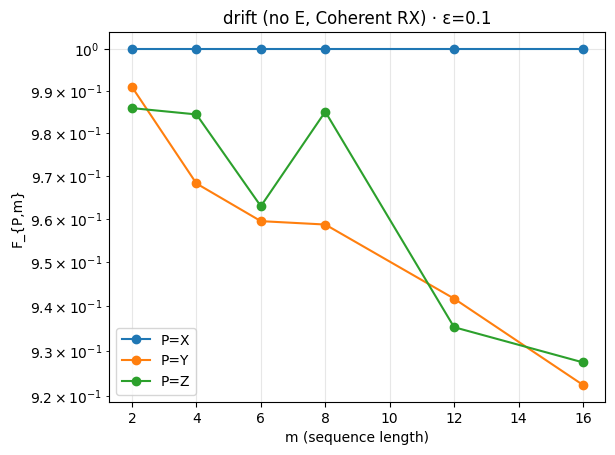

In [5]:
# Driver for Drift with no env qubit

eps = 0.1
drift_rng    = np.random.default_rng(42)    
drift_cfg    = CBConfig(n_sys_qubits=1, n_env=0, shots=1024,
                        m_list=(2,4,6,8,12,16), L=30, K=30,
                        rng=drift_rng, label="CB_Cycle",
                        env_coupling_gate=make_drift(eps),
                        reset_env=False)  

drift_paulis = make_paulis(drift_cfg.n_sys_qubits, drift_cfg.rng, drift_cfg.K)
drift_Gmap, _ = make_cycle("I", drift_cfg.n_sys_qubits)
drift_Ggate = UnitaryGate(Operator(drift_Gmap).data, label=drift_cfg.label)
drift_sampler = AerSampler()
records_drift = run_cb(drift_paulis, drift_cfg, drift_Gmap, drift_Ggate, drift_sampler)
plot_decay(records_drift, drift_cfg, title=f"drift (no E, Coherent RX) · ε={eps}")

In [6]:
# helper for training data generation
print(records_drift.keys())
print(records_drift["Y"].keys())
print(records_drift["Y"][6])

dict_keys(['X', 'Y', 'Z'])
dict_keys([2, 4, 6, 8, 12, 16])
[{'counts': {'0': 9, '1': 1015}, 'pauli_sign': -1, 'twirl_seq': ['Y', 'X', 'Z', 'X', 'Z', 'X', 'I']}, {'counts': {'1': 1024}, 'pauli_sign': -1, 'twirl_seq': ['Z', 'I', 'Z', 'I', 'I', 'Y', 'Z']}, {'counts': {'0': 37, '1': 987}, 'pauli_sign': -1, 'twirl_seq': ['X', 'I', 'I', 'Z', 'Y', 'I', 'X']}, {'counts': {'0': 8, '1': 1016}, 'pauli_sign': -1, 'twirl_seq': ['X', 'I', 'Z', 'Y', 'I', 'Y', 'X']}, {'counts': {'1': 38, '0': 986}, 'pauli_sign': 1, 'twirl_seq': ['I', 'X', 'I', 'I', 'Z', 'Y', 'I']}, {'counts': {'1': 1024}, 'pauli_sign': -1, 'twirl_seq': ['Z', 'Y', 'Z', 'Y', 'X', 'Y', 'Y']}, {'counts': {'1': 91, '0': 933}, 'pauli_sign': 1, 'twirl_seq': ['Y', 'I', 'X', 'I', 'X', 'I', 'I']}, {'counts': {'1': 11, '0': 1013}, 'pauli_sign': 1, 'twirl_seq': ['Z', 'I', 'Z', 'I', 'Z', 'X', 'Y']}, {'counts': {'0': 12, '1': 1012}, 'pauli_sign': -1, 'twirl_seq': ['X', 'X', 'X', 'Y', 'X', 'Y', 'Z']}, {'counts': {'1': 88, '0': 936}, 'pauli_sign': 1,

In [7]:
# quick check: one run → dataframe
records_df = records_to_dataframe(records_drift, {"noisetype": "drift", "param": "eps", "param_value": eps, "seed": 42})
print(records_df.tail())


    noisetype param  param_value  seed  P   m   l     f_pml  n_plus  n_minus  \
535     drift   eps          0.1    42  Z  16  25  0.978516    1013       11   
536     drift   eps          0.1    42  Z  16  26  0.974609    1011       13   
537     drift   eps          0.1    42  Z  16  27  0.916016     981       43   
538     drift   eps          0.1    42  Z  16  28  0.787109     109      915   
539     drift   eps          0.1    42  Z  16  29  1.000000    1024        0   

     pauli_sign                                          twirl_seq  
535           1  [I, X, Y, I, I, Z, Y, X, Z, Z, X, Y, I, X, Y, ...  
536           1  [Z, X, X, I, Y, I, X, Y, Y, Y, I, Z, Y, Z, X, ...  
537           1  [Z, I, I, Y, Y, Y, X, Z, X, Y, Z, Y, Y, Z, Z, ...  
538          -1  [I, Y, Z, X, X, I, X, I, Z, Y, I, I, Z, Z, Z, ...  
539           1  [I, Z, Z, Z, I, I, Z, Z, Y, I, I, I, Y, Z, Y, ...  


In [8]:
# Driver for checkpoint save cranked up
# ===== Generate the dataset: 30 seeds per (noise type, dial) =====
base  = dict(n_sys_qubits=1, shots=1024, m_list=(2,4,6,8,12,16), L=30, K=30, cycle="I")
seeds = list(range(30))          # 30 seeds → ~15× more examples (skips the 30 already on disk)

# memory & jitter — δ dials
sweep(classes=["memory", "jitter"], params=[0.05, 0.10, 0.15, 0.20], seeds=seeds, base=base)

# drift — wider ε dials (needs bigger ε to reach the same decay)
sweep(classes=["drift"], params=[0.05, 0.10, 0.15, 0.20, 0.40, 0.60, 0.80], seeds=seeds, base=base)


skip (done): memory_delta0.050_seed0.parquet
skip (done): memory_delta0.050_seed1.parquet
Running for 3 Paulis: ['X', 'Y', 'Z']
[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.4s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.8s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.1s)
saved: memory_delta0.050_seed2.parquet
Running for 3 Paulis: ['X', 'Y', 'Z']
[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.4s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.7s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.1s)
saved: memory_delta0.050_seed3.parquet
Running for 3 Paulis: ['X', 'Y', 'Z']
[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.3s)
[ 2/3] P=Y    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 0.7s)
[ 3/3] P=Z    m=[2, 4, 6, 8, 12, 16] × 30 seqs [L]  (elapsed 1.1s)
saved: memory_delta0.050_seed4.parquet
Running for 3 Paulis: ['X', 'Y', 'Z']
[ 1/3] P=X    m=[2, 4, 6, 8, 12, 16] ×

In [9]:
# quick check on created files

import pandas as pd
from pathlib import Path

DATA_DIR = Path("data")
files  = sorted(DATA_DIR.glob("*.parquet"))
df_all = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

print("files:", len(files))                       # → 24
print("rows :", len(df_all))
print(df_all.groupby("noisetype").size())          # → 4320 each
df_all.head()


files: 450
rows : 243000
noisetype
drift     113400
jitter     64800
memory     64800
dtype: int64


,noisetype,param,param_value,seed,P,m,l,f_pml,n_plus,n_minus,pauli_sign,twirl_seq
0,drift,eps,0.05,0,X,2,0,1.0,0,1024,-1,"[Z, Y, Y]"
1,drift,eps,0.05,0,X,2,1,1.0,1024,0,1,"[X, X, I]"
2,drift,eps,0.05,0,X,2,2,1.0,1024,0,1,"[I, I, I]"
3,drift,eps,0.05,0,X,2,3,1.0,0,1024,-1,"[Z, Y, Z]"
4,drift,eps,0.05,0,X,2,4,1.0,0,1024,-1,"[Y, Y, Z]"
